# Resorte — ajuste lineal a partir de mediciones
**Objetivo:** conservar el cálculo manual de la recta de clase y comprobarlo con `np.polyfit`. La pendiente conecta datos con la ley de Hooke.

## 1. Lectura y gráfico con incertidumbres
Columnas: masa $m\pm\Delta m$ en **g** y elongación $x\pm\Delta x$ en **cm**.

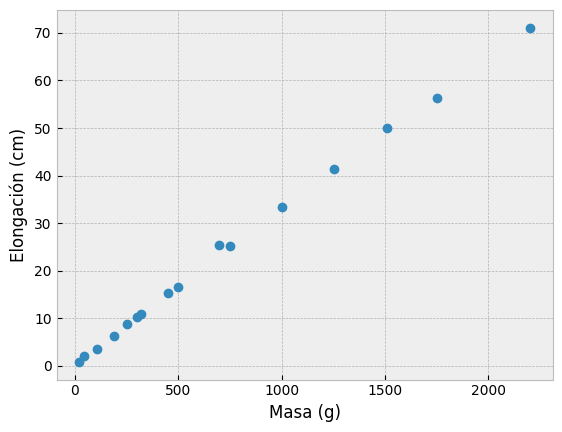

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('bmh')

datos = np.genfromtxt('datos_mediciones_laboratorio-v2.txt', skip_header=2)
m, Dm, x, Dx = datos.T
plt.errorbar(m, x, xerr=Dm, yerr=Dx, fmt='o', capsize=3)
plt.xlabel('Masa (g)')
plt.ylabel('Elongación (cm)')
plt.show()

## 2. Calcular la recta manualmente
Modelo $x=a_0+a_1m$. Como en el notebook de clase, usamos $a_1=\big(\overline{mx}-\bar m\bar x\big)/(\overline{m^2}-\bar m^2)$ y $a_0=\bar x-a_1\bar m$.

In [2]:
a1 = (np.mean(m*x) - np.mean(m)*np.mean(x)) / (np.mean(m**2) - np.mean(m)**2)
a0 = np.mean(x) - a1*np.mean(m)
a1_pf, a0_pf = np.polyfit(m, x, 1)
print(f'Manual: a0={a0:.4f} cm, a1={a1:.5f} cm/g')
print(f'polyfit: a0={a0_pf:.4f} cm, a1={a1_pf:.5f} cm/g')
assert np.allclose([a1,a0],[a1_pf,a0_pf])

Manual: a0=0.6494 cm, a1=0.03230 cm/g
polyfit: a0=0.6494 cm, a1=0.03230 cm/g


## 3. Mostrar el ajuste e interpretar la pendiente
En equilibrio $mg=kx$, por tanto $a_1=g/k$ si trabajamos en **SI**. La pendiente en cm/g debe convertirse: $1\,\mathrm{cm/g}=10\,\mathrm{m/kg}$.

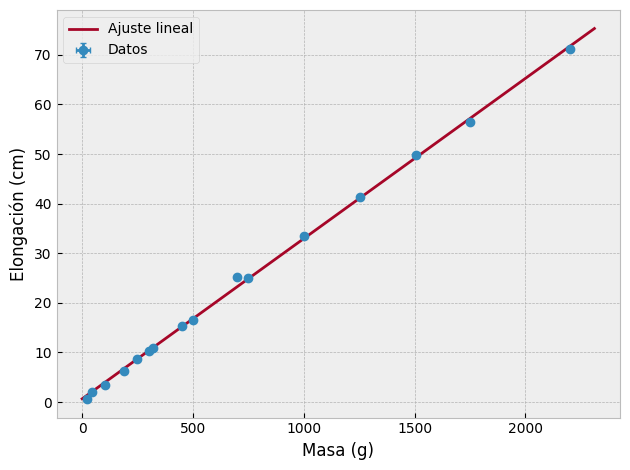

Constante elástica estimada: k = 30.37 N/m


In [3]:
m_recta = np.linspace(0, m.max()*1.05, 200)
plt.errorbar(m, x, xerr=Dm, yerr=Dx, fmt='o', capsize=2, label='Datos')
plt.plot(m_recta, a0 + a1*m_recta, label='Ajuste lineal')
plt.xlabel('Masa (g)')
plt.ylabel('Elongación (cm)')
plt.legend()
plt.tight_layout()
plt.show()

pendiente_SI = a1 * 10  # (cm/g) -> (m/kg)
k = 9.81 / pendiente_SI
print(f'Constante elástica estimada: k = {k:.2f} N/m')

**Alcance:** este es un ajuste ordinario que no pondera las mediciones según sus incertidumbres y no calcula la incertidumbre de $k$. Un intercepto diferente de cero puede reflejar una referencia inicial desplazada.

**Comprueba:** ¿por qué `np.polyfit(m, x, 2)` devuelve **tres** coeficientes y no dos? ¿Por qué la pendiente debe convertirse a SI antes de calcular $k$?